<a href="https://colab.research.google.com/github/ivansuarez-AU/MAI510_M3_Assignment_3_1/blob/main/MAI510_M3_Assignment_3_1_Complete_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 510 · Module 3 · Assignment 3.1
## StreamSense AI — Train It, Test It, Trick It!
**Complete instructor demonstration + student lab** | Google Colab | IMDB sentiment analysis

**What you will produce:** a student-named LSTM `.keras` model, training/validation charts, accuracy/precision/recall/F1, three sequence-length experiments, a 20-error evidence CSV, an HTML dashboard, and a named Word **1–2-page editable analysis draft** with prompts, plus a submission ZIP. An optional challenge tests student-authored reviews; optional Ollama runs a small generative model on the *same* review separately. The Ollama output is **not** the graded LSTM output.

**Before starting:** `Runtime → Change runtime type → T4 GPU` if available (CPU works but is slower). Run cells top to bottom. **Do not put private or copyrighted full reviews in external AI services.**

**Success requirements:** Complete the *FULL* mode for graded results, categorize 20 actual errors, and write evidence-based conclusions in the Word report. DEMO mode is for classroom illustration only.

## LAB 0 — Register student and assignment (REQUIRED)
When the prompt appears, enter your **full name** (for example, Ivan Suarez). The assignment title is requested explicitly. The name and assignment are embedded in every generated report and ZIP filename.

In [1]:
from pathlib import Path
import re, os, sys, time, json, subprocess, zipfile, platform
from datetime import datetime, timezone

STUDENT_NAME = input('Enter your full name (e.g., Ivan Suarez): ').strip()
while len(STUDENT_NAME.split()) < 2 or STUDENT_NAME.lower() in {'your name','student name'}:
    print('Please enter your first and last name.')
    STUDENT_NAME = input('Enter your FULL name: ').strip()
ASSIGNMENT_NAME = input('Enter assignment (press Enter for Assignment 3.1): ').strip() or 'Assignment 3.1'
COURSE = 'MAI 510 — Deep Learning'
if '3.1' not in ASSIGNMENT_NAME:
    raise ValueError('This notebook is for Assignment 3.1. Enter Assignment 3.1 and rerun this cell.')
SAFE_NAME = re.sub(r'[^A-Za-z0-9]+','_',STUDENT_NAME).strip('_')
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
OUT = Path('/content') / f'MAI510_M3_A31_{SAFE_NAME}_{RUN_ID}'
OUT.mkdir(parents=True,exist_ok=True)
print('REGISTERED:', STUDENT_NAME, '|', ASSIGNMENT_NAME, '\nEvidence folder:', OUT)

Enter your full name (e.g., Ivan Suarez): Ivan Suarez
Enter assignment (press Enter for Assignment 3.1): Assignment 3.1
REGISTERED: Ivan Suarez | Assignment 3.1 
Evidence folder: /content/MAI510_M3_A31_Ivan_Suarez_20261111_003138


## LAB 1 — Setup, reproducibility, and workload
Start with `DEMO_MODE=True` while teaching. Change to `False`, restart, and run top-to-bottom for a final student submission. Both modes execute all three sequence-length experiments, but DEMO uses fewer examples/epochs.

In [2]:
%pip -q install python-docx plotly scikit-learn pandas matplotlib nbformat
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
import plotly.express as px, plotly.graph_objects as go
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from IPython.display import display, HTML

DEMO_MODE = True              # Change to False for FINAL assignment
VOCAB_SIZE = 10000
SEQUENCE_LENGTHS = [100, 200, 300]
BASE_LENGTH = 200
BATCH_SIZE = 64
EMBED_DIM, LSTM_UNITS = 32, 32  # Consistent across experiments
EPOCH_BUDGET = 2 if DEMO_MODE else 8
TRAIN_LIMIT = 3000 if DEMO_MODE else 18000
VALID_LIMIT = 600 if DEMO_MODE else 4000
TEST_LIMIT = 2500 if DEMO_MODE else None
SEED=42
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:',tf.__version__,'| GPU:',tf.config.list_physical_devices('GPU'))
print('MODE:', 'SHORT INSTRUCTOR DEMO (not final)' if DEMO_MODE else 'FULL STUDENT EXPERIMENT')
print('All 3 lengths are trained; no metrics are fabricated.')

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
MODE: SHORT INSTRUCTOR DEMO (not final)
All 3 lengths are trained; no metrics are fabricated.


## LAB 2 — Load IMDB and decode sequences
IMDB provides 25,000 training reviews and 25,000 test reviews, binary labels (0 = negative, 1 = positive). We split the original training partition into **training and validation**, leaving the official test partition for final evaluation. Do not tune based on test results.

In [3]:
(raw_x,raw_y),(raw_xt,raw_yt)=imdb.load_data(num_words=VOCAB_SIZE)
raw_y=np.asarray(raw_y); raw_yt=np.asarray(raw_yt)
rng=np.random.default_rng(SEED)
all_indices=rng.permutation(len(raw_x))
valid_idx=all_indices[:VALID_LIMIT]
train_idx=all_indices[VALID_LIMIT:VALID_LIMIT+TRAIN_LIMIT]
test_idx=np.arange(len(raw_xt)) if TEST_LIMIT is None else np.arange(TEST_LIMIT)
train_reviews=[raw_x[int(i)] for i in train_idx]
valid_reviews=[raw_x[int(i)] for i in valid_idx]
test_reviews=[raw_xt[int(i)] for i in test_idx]
y_train=raw_y[train_idx];y_valid=raw_y[valid_idx];y_test=raw_yt[test_idx]
word_index=imdb.get_word_index()
reverse_index={i+3:w for w,i in word_index.items()}
reverse_index.update({0:'<PAD>',1:'<START>',2:'<UNK>',3:'<UNUSED>'})
def decode_review(seq, max_words=None):
    tokens=[reverse_index.get(int(i),'<UNK>') for i in seq]
    return ' '.join(tokens if max_words is None else tokens[:max_words])
print('Train',len(train_reviews),'Valid',len(valid_reviews),'Test',len(test_reviews))
print('Example label:', 'positive' if y_train[0] else 'negative')
print('Example decoded text:', decode_review(train_reviews[0],80))
print('Review lengths (min, median, max):',np.min([len(x) for x in train_reviews]),np.median([len(x) for x in train_reviews]),np.max([len(x) for x in train_reviews]))
assert set(train_idx).isdisjoint(set(valid_idx)), 'Training/validation overlap!'
assert len(test_reviews)>0

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train 3000 Valid 600 Test 2500
Example label: negative
Example decoded text: <START> i like bad movies i like to rent bad movies with my friends and rip on them for their duration then there are <UNK> movies like this <UNK> is not just a bad movie but a telling sign that maybe the american movie industry should please for the sake of the viewer at least <UNK> scripts before funding a movie br br if a stereotype took a crap this movie would <UNK> from that the storyline is unbearable and
Review lengths (min, median, max): 19 180.0 1300


## LAB 3 — Human vs AI mini-challenge
Before showing labels, read three excerpts and predict their sentiment. Answer in discussion; **no model claims** here.

In [4]:
human_rows=[]
for j in range(3):
    human_rows.append({'Review ID':j,'Excerpt':decode_review(valid_reviews[j],55),'Actual label (reveal after votes)':'positive' if y_valid[j] else 'negative'})
display(pd.DataFrame(human_rows))
print('Class discussion: Which phrases or negations influenced your decisions?')

,Review ID,Excerpt,Actual label (reveal after votes)
0,0,<START> if you are already a fan of peter <UNK...,positive
1,1,<START> the fact that this movie has been enti...,negative
2,2,<START> hard to describe this one if you were ...,negative


Class discussion: Which phrases or negations influenced your decisions?


## LAB 4 — Padding and truncation: see what disappears
`padding="post"` adds zeros at the end; `truncating="pre"` removes earlier words from overly long reviews. Right-side padding is more compatible with accelerated LSTM execution. The sequence-length experiment demonstrates the information/compute tradeoff.

Original length: 1300
100 tokens: retained 100; preview of retained text: victor vargas reminds me of those guys who were getting laid while i was playing with my <UNK> <UNK> when i was <UNK> maybe it's because without any further <UNK> by the film victor vargas
200 tokens: retained 200; preview of retained text: was wrong but after speaking with my grandmother i knew my problem with this was justified considering how conservative the grandmother is you'd think that <UNK> would have been sleeping in her room br br
300 tokens: retained 300; preview of retained text: <UNK> white kids the results wouldn't be such glowing reviews and we'd see the film's flaws more clearly indeed some other aspects of the use of <UNK> in this film bother me while some aspects


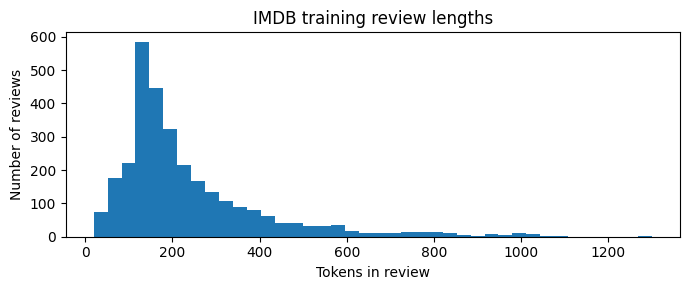

In [5]:
example=max(train_reviews, key=len)
print('Original length:',len(example))
for n in SEQUENCE_LENGTHS:
    processed=pad_sequences([example], maxlen=n, padding='post', truncating='pre')[0]
    kept=[int(i) for i in processed if i != 0]
    print(f'{n} tokens: retained {len(kept)}; preview of retained text:', decode_review(kept,35))
fig,ax=plt.subplots(figsize=(7,3));ax.hist([len(x) for x in train_reviews],bins=40)
ax.set(title='IMDB training review lengths',xlabel='Tokens in review',ylabel='Number of reviews')
fig.tight_layout();fig.savefig(OUT/'review_length_histogram.png',dpi=160);plt.show()

## LAB 5 — Define the SAME LSTM architecture for every experiment
Embedding maps word IDs to learned dense vectors. LSTM remembers sequence information. Sigmoid outputs a probability for positive sentiment. Using unchanged architecture and data splits ensures the main comparison variable is sequence length.

In [6]:
def make_model(length):
    m=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(length,)),
        tf.keras.layers.Embedding(VOCAB_SIZE,EMBED_DIM,mask_zero=True),
        tf.keras.layers.LSTM(LSTM_UNITS),
        tf.keras.layers.Dense(1,activation='sigmoid')
    ],name=f'Sentiment_LSTM_{length}')
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m
preview_model=make_model(BASE_LENGTH)
preview_model.summary()

Model: "Sentiment_LSTM_200"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,353 (1.25 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

## LAB 6 — Train all three sequence lengths (required)
This can take several minutes per run, especially on CPU. `EarlyStopping` monitors validation loss, restores the best epoch, and limits wasted training. Training time is measured wall-clock time (not a prediction).

In [7]:
from time import perf_counter
EXPERIMENTS={}; comparison=[]; history_rows=[]
for length in SEQUENCE_LENGTHS:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    Xtr=pad_sequences(train_reviews,maxlen=length,padding='post',truncating='pre')
    Xva=pad_sequences(valid_reviews,maxlen=length,padding='post',truncating='pre')
    Xte=pad_sequences(test_reviews,maxlen=length,padding='post',truncating='pre')
    model=make_model(length)
    cb=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)
    t0=perf_counter()
    hist=model.fit(Xtr,y_train,validation_data=(Xva,y_valid),epochs=EPOCH_BUDGET,
                   batch_size=BATCH_SIZE,verbose=1,callbacks=[cb],shuffle=True)
    train_seconds=perf_counter()-t0
    probabilities=model.predict(Xte,batch_size=256,verbose=0).ravel()
    predicted=(probabilities>=0.5).astype(int)
    metrics={'Length':length,'Accuracy':accuracy_score(y_test,predicted),
             'Precision':precision_score(y_test,predicted,zero_division=0),
             'Recall':recall_score(y_test,predicted,zero_division=0),
             'F1':f1_score(y_test,predicted,zero_division=0),
             'Training seconds':train_seconds,'Epochs completed':len(hist.history['loss']),
             'Best val-loss epoch':int(np.argmin(hist.history['val_loss'])+1)}
    comparison.append(metrics)
    for ep in range(len(hist.history['loss'])):
        history_rows.append({'Length':length,'Epoch':ep+1,**{k:float(v[ep]) for k,v in hist.history.items()}})
    path=OUT/f'LSTM_sequence_{length}.keras'
    model.save(path)
    EXPERIMENTS[length]={'model':model,'history':hist.history,'pred':predicted,'probs':probabilities,'metrics':metrics}
    print('Saved',path,'|',metrics)
comparison_df=pd.DataFrame(comparison)
history_df=pd.DataFrame(history_rows)
comparison_df.to_csv(OUT/'three_length_metrics.csv',index=False)
history_df.to_csv(OUT/'training_history_all_lengths.csv',index=False)
display(comparison_df.round(4))

Epoch 1/2
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.5483 - loss: 0.6893 - val_accuracy: 0.6883 - val_loss: 0.6710
Epoch 2/2
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7690 - loss: 0.5139 - val_accuracy: 0.7917 - val_loss: 0.4466
Saved /content/MAI510_M3_A31_Ivan_Suarez_20261111_003138/LSTM_sequence_100.keras | {'Length': 100, 'Accuracy': 0.7988, 'Precision': 0.8035242290748899, 'Recall': 0.7651006711409396, 'F1': 0.7838418564675548, 'Training seconds': 5.60744583799999, 'Epochs completed': 2, 'Best val-loss epoch': 2}
Epoch 1/2
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.5483 - loss: 0.6893 - val_accuracy: 0.6883 - val_loss: 0.6710
Epoch 2/2
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7810 - loss: 0.5199 - val_accuracy: 0.8217 - val_loss: 0.4582
Saved /content/MAI510_M3_A31_Ivan_Suarez_20261111_003138/LSTM_sequence_200.keras | {'Length': 200, 'Accuracy': 0.806, 'Precision': 0.8503468780971258, 'Recall': 0.7197986577181208, 'F1': 0.779645615629

,Length,Accuracy,Precision,Recall,F1,Training seconds,Epochs completed,Best val-loss epoch
0,100,0.7988,0.8035,0.7651,0.7838,5.6074,2,2
1,200,0.8060,0.8503,0.7198,0.7796,5.3276,2,2
2,300,0.8164,0.8347,0.7668,0.7993,3.1612,2,2


## LAB 7 — Required training curves + mark the best validation-loss epoch
An overfitting signal is **training loss falling while validation loss rises**. The epoch with minimum validation loss is visible on every plot. If demo mode does not reveal overfitting, say so honestly.

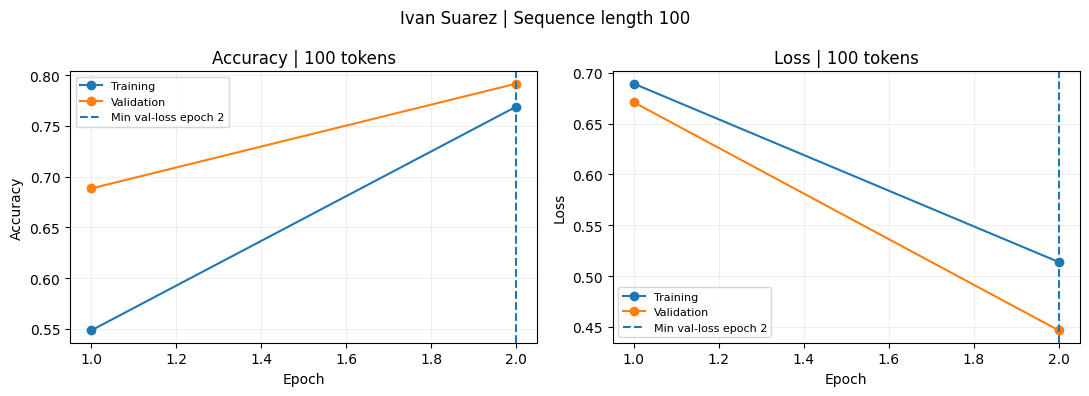

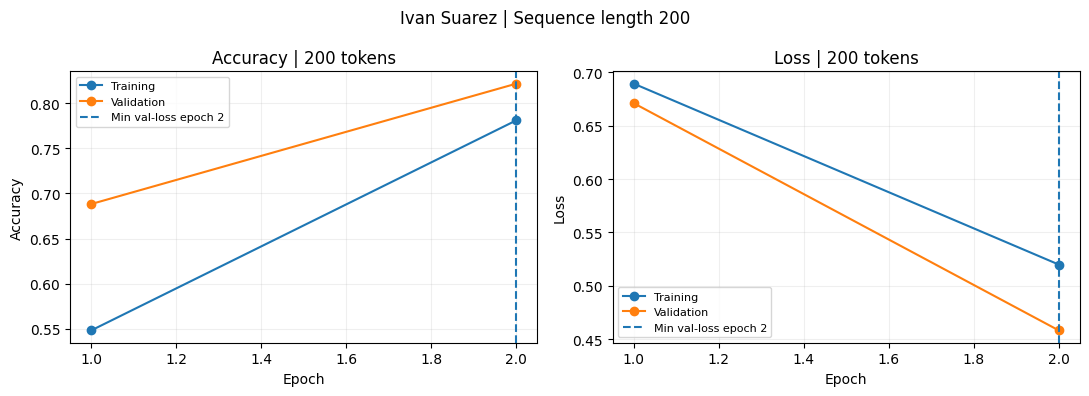

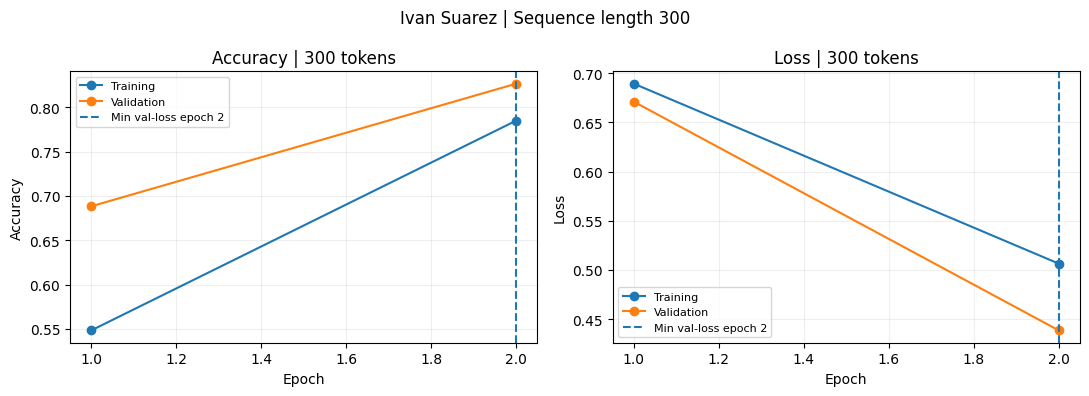

Discuss: which curves show real evidence of overfitting?


In [8]:
for length in SEQUENCE_LENGTHS:
    hist=EXPERIMENTS[length]['history']; ep=np.arange(1,len(hist['loss'])+1)
    best=int(np.argmin(hist['val_loss'])+1)
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    axs[0].plot(ep,hist['accuracy'],marker='o',label='Training')
    axs[0].plot(ep,hist['val_accuracy'],marker='o',label='Validation')
    axs[0].set(title=f'Accuracy | {length} tokens',xlabel='Epoch',ylabel='Accuracy')
    axs[1].plot(ep,hist['loss'],marker='o',label='Training')
    axs[1].plot(ep,hist['val_loss'],marker='o',label='Validation')
    axs[1].set(title=f'Loss | {length} tokens',xlabel='Epoch',ylabel='Loss')
    for ax in axs:
        ax.axvline(best,ls='--',label=f'Min val-loss epoch {best}')
        ax.legend(fontsize=8);ax.grid(alpha=0.2)
    fig.suptitle(f'{STUDENT_NAME} | Sequence length {length}')
    fig.tight_layout();fig.savefig(OUT/f'training_curves_{length}.png',dpi=170);plt.show()
print('Discuss: which curves show real evidence of overfitting?')

## LAB 8 — Required accuracy, precision, recall, F1 and confusion matrix
Positive is class 1. These are **test set** measurements for the saved best-weight checkpoint of the selected reference model. The selected model is the 200-token reference, fixed in advance rather than selected by test performance.

              precision    recall  f1-score   support

    Negative     0.7760    0.8846    0.8267      1308
    Positive     0.8503    0.7198    0.7796      1192

    accuracy                         0.8060      2500
   macro avg     0.8132    0.8022    0.8032      2500
weighted avg     0.8114    0.8060    0.8043      2500



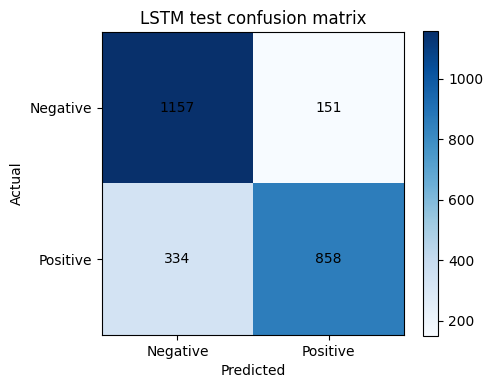

Reference model: 200 tokens. Report accuracy, precision, recall, F1 above.


In [9]:
ref=EXPERIMENTS[BASE_LENGTH]
cm=confusion_matrix(y_test,ref['pred'],labels=[0,1])
print(classification_report(y_test,ref['pred'],target_names=['Negative','Positive'],digits=4))
fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(cm,cmap='Blues')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Negative','Positive'],yticklabels=['Negative','Positive'],xlabel='Predicted',ylabel='Actual',title='LSTM test confusion matrix')
for (r,c),v in np.ndenumerate(cm):ax.text(c,r,str(v),ha='center',va='center',color='black')
fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/'test_confusion_matrix.png',dpi=170);plt.show()
ref_metrics=pd.DataFrame([ref['metrics']]);ref_metrics.to_csv(OUT/'reference_test_metrics.csv',index=False)
print('Reference model:',BASE_LENGTH,'tokens. Report accuracy, precision, recall, F1 above.')

## LAB 9 — Interactive dashboard + evidence graphics
Plotly HTML works offline once exported; the embedded interactive charts are intended for instructor demonstration and evidence, not a claim that a deployed web server exists.

In [10]:
plot_df=comparison_df.melt(id_vars=['Length'],value_vars=['Accuracy','Precision','Recall','F1'],var_name='Metric',value_name='Score')
chart1=px.bar(plot_df,x='Length',y='Score',color='Metric',barmode='group',title='LSTM: Three Sequence Lengths vs Test Metrics')
chart2=px.bar(comparison_df,x='Length',y='Training seconds',title='Training Time vs Sequence Length')
chart3=px.line(history_df,x='Epoch',y='val_loss',color=history_df['Length'].astype(str),markers=True,title='Validation Loss Across Sequence Lengths')
from plotly.subplots import make_subplots
from plotly.io import to_html
html_page=f"""<!doctype html><html><head><meta charset="utf-8"><title>MAI 510 | {STUDENT_NAME}</title>
<style>body{{font-family:Arial,sans-serif;margin:32px;max-width:1250px}}h1{{color:#143458}}.subtitle{{color:#555}}</style></head><body>
<h1>MAI 510 — Assignment 3.1 | {STUDENT_NAME}</h1>
<p class="subtitle">{ASSIGNMENT_NAME} · {'DEMO - NOT FINAL' if DEMO_MODE else 'FULL EXPERIMENT'} · IMDB LSTM</p>
{to_html(chart1,full_html=False,include_plotlyjs=True)}
{to_html(chart2,full_html=False,include_plotlyjs=False)}
{to_html(chart3,full_html=False,include_plotlyjs=False)}
<p><b>Interpretation is written by the student in the report, not generated by these figures.</b></p></body></html>"""
(OUT/'interactive_dashboard.html').write_text(html_page,encoding='utf-8')
chart1.write_image if False else None
chart1.show();chart2.show();chart3.show()
print('Saved interactive HTML dashboard.')

Saved interactive HTML dashboard.


## LAB 10 — Collect twenty REAL model errors (required)
This identifies **incorrectly classified labeled IMDB test reviews**, preserving actual and predicted classes and the model confidence. Categorizing *why* they failed remains a human interpretation, not something the network can know. Save CSV and optionally upload an edited copy after review.

In [11]:
wrong=np.where(ref['pred']!=y_test)[0]
print('Total mistakes available:',len(wrong),'out of',len(y_test))
if len(wrong)<20:
    raise RuntimeError('Fewer than 20 mistakes in selected test slice. Increase TEST_LIMIT or rerun FULL mode.')
rows=[]
for k,idx in enumerate(wrong[:20],start=1):
    p=float(ref['probs'][idx]); pred=int(ref['pred'][idx]); actual=int(y_test[idx])
    rows.append({'Error #':k,'Test index':int(idx),'Actual sentiment':'Positive' if actual else 'Negative',
                 'Predicted sentiment':'Positive' if pred else 'Negative',
                 'Confidence of predicted class':float(p if pred==1 else 1-p),
                 'Review token length':len(test_reviews[idx]),'Decoded review':decode_review(test_reviews[idx]),
                 'Primary failure category':'UNREVIEWED',
                 'Evidence / explanation (student writes)':''})
errors_df=pd.DataFrame(rows)
errors_csv=OUT/'20_incorrect_reviews_FOR_STUDENT_CATEGORIZATION.csv'
errors_df.to_csv(errors_csv,index=False)
display(errors_df[['Error #','Actual sentiment','Predicted sentiment','Confidence of predicted class','Review token length','Primary failure category']])
print('Evidence saved to', errors_csv)
print('Allowed categories: Negation / Sarcasm / Length or truncation / Other or uncertain.')
print('Read the text and identify supporting evidence before making a claim about failure cause.')

Total mistakes available: 485 out of 2500


,Error #,Actual sentiment,Predicted sentiment,Confidence of predicted class,Review token length,Primary failure category
0,1,Positive,Negative,0.789758,603,UNREVIEWED
1,2,Negative,Positive,0.582386,181,UNREVIEWED
2,3,Negative,Positive,0.523914,134,UNREVIEWED
3,4,Positive,Negative,0.534675,370,UNREVIEWED
4,5,Positive,Negative,0.721787,232,UNREVIEWED
5,6,Positive,Negative,0.800873,133,UNREVIEWED
6,7,Negative,Positive,0.573116,121,UNREVIEWED
7,8,Positive,Negative,0.541302,228,UNREVIEWED
8,9,Negative,Positive,0.563154,132,UNREVIEWED
9,10,Positive,Negative,0.716936,132,UNREVIEWED


Evidence saved to /content/MAI510_M3_A31_Ivan_Suarez_20261111_003138/20_incorrect_reviews_FOR_STUDENT_CATEGORIZATION.csv
Allowed categories: Negation / Sarcasm / Length or truncation / Other or uncertain.
Read the text and identify supporting evidence before making a claim about failure cause.


## LAB 11 — Optional: upload your completed failure-analysis CSV
Open the CSV, fill the failure-category and explanation columns for all 20 rows, and upload it. No automatic labels are invented. This can be done after classroom demo and before final ZIP export.

In [12]:
# OPTIONAL: set this True after you have edited the exported CSV on your computer.
UPLOAD_REVIEWED_CSV = False
if UPLOAD_REVIEWED_CSV:
    from google.colab import files
    uploads=files.upload()
    if not uploads: raise ValueError('No CSV uploaded.')
    fn=next(iter(uploads))
    updated=pd.read_csv(fn)
    required={'Error #','Primary failure category','Evidence / explanation (student writes)'}
    assert required.issubset(updated.columns),'CSV missing required columns'
    assert len(updated)==20, 'Expected exactly 20 error analyses'
    updated.to_csv(OUT/'20_incorrect_reviews_REVIEWED.csv',index=False)
    errors_df=updated
    print('Saved reviewed evidence. Category counts:')
    print(errors_df['Primary failure category'].value_counts(dropna=False))
else:
    print('Optional upload skipped. The exported CSV is marked UNREVIEWED until students complete it.')

Optional upload skipped. The exported CSV is marked UNREVIEWED until students complete it.


## LAB 12 — Optional classroom challenge: fool the LSTM
Enter your own tricky movie reviews. This is **not** a replacement for twenty *labeled test-set mistakes*. Since these are student-created, their sentiment labels are subjective. IMDB vocabulary maps unknown words to an unknown token.

In [13]:
OPTIONAL_CHALLENGE = True
classroom_reviews=[
 'I expected a terrible movie, but it was surprisingly wonderful.',
 'Oh great, another two hours of my life I will never get back.',
 'The actors were fantastic, although the story was a complete mess.'
]
if OPTIONAL_CHALLENGE:
    def encode_free_text(text,length=BASE_LENGTH):
        tokens=re.findall(r"[a-z']+",text.lower())
        ids=[1]+[word_index.get(w,0)+3 if w in word_index and word_index[w]+3<VOCAB_SIZE else 2 for w in tokens]
        return pad_sequences([ids],maxlen=length,padding='post',truncating='pre')
    challenge_rows=[]
    for text in classroom_reviews:
        p=float(ref['model'].predict(encode_free_text(text),verbose=0)[0,0])
        challenge_rows.append({'Review':text,'Model sentiment':'Positive' if p>=.5 else 'Negative','Positive probability':round(p,4),'Student intended sentiment':'DISCUSS IN CLASS'})
    pd.DataFrame(challenge_rows).to_csv(OUT/'OPTIONAL_classroom_challenge.csv',index=False)
    display(pd.DataFrame(challenge_rows))

,Review,Model sentiment,Positive probability,Student intended sentiment
0,"I expected a terrible movie, but it was surpri...",Negative,0.4283,DISCUSS IN CLASS
1,"Oh great, another two hours of my life I will ...",Positive,0.6831,DISCUSS IN CLASS
2,"The actors were fantastic, although the story ...",Negative,0.4859,DISCUSS IN CLASS


## LAB 13 — OPTIONAL: run a small Ollama model **inside Colab**
Ollama is a separate generative model demonstration, **not an LSTM**, and must not replace the graded test metrics. Installing the Ollama Linux service and downloading a model may take time or fail on Colab temporary VM and can compete for RAM/GPU. For portability, this cell does nothing unless you set `RUN_OLLAMA=True`. Only use public or self-authored short examples. Ollama official documentation: https://ollama.com/download/linux and https://ollama.com/library/gemma3 .

In [16]:

# ============================================================
# MAI 510 - MODULE 3 - ASSIGNMENT 3.1
# LAB 13 - OPTIONAL OLLAMA DEMONSTRATION
# ============================================================

RUN_OLLAMA = True
OLLAMA_MODEL = "gemma3:270m"

import os
import sys
import time
import shutil
import subprocess
import urllib.request
from pathlib import Path

# Use existing assignment output folder
try:
    output_dir = Path(OUT)
except NameError:
    output_dir = Path("/content/MAI510_Ollama_Demo")

output_dir.mkdir(parents=True, exist_ok=True)

def ollama_ready():
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:11434/api/tags",
            timeout=3
        ) as response:
            return response.status == 200
    except Exception:
        return False

if not RUN_OLLAMA:
    print("Ollama skipped. Assignment 3.1 remains unaffected.")

else:
    try:
        print("=" * 60)
        print("MAI 510 - OPTIONAL OLLAMA DEMONSTRATION")
        print("=" * 60)

        # STEP 1 - INSTALL OLLAMA
        if shutil.which("ollama") is None:

            print("\nDownloading official Ollama installer...")

            installer_path = "/tmp/ollama_install.sh"

            urllib.request.urlretrieve(
                "https://ollama.com/install.sh",
                installer_path
            )

            print("Running installer...")

            install = subprocess.run(
                ["sh", installer_path],
                capture_output=True,
                text=True,
                timeout=180
            )

            if install.returncode != 0:
                raise RuntimeError(
                    "Ollama installation failed:\n"
                    + install.stdout[-1500:]
                    + "\n"
                    + install.stderr[-1500:]
                )

            print("Ollama installed successfully.")

        else:
            print("Ollama is already installed.")

        # STEP 2 - CHECK VERSION
        version = subprocess.run(
            ["ollama", "--version"],
            capture_output=True,
            text=True
        )

        print("Version:", version.stdout.strip())

        # STEP 3 - START LOCAL SERVER
        if not ollama_ready():

            print("\nStarting Ollama server...")

            log_path = output_dir / "OPTIONAL_ollama_server.log"

            log_file = open(log_path, "w")

            server = subprocess.Popen(
                ["ollama", "serve"],
                stdout=log_file,
                stderr=subprocess.STDOUT,
                start_new_session=True
            )

            for attempt in range(30):
                if ollama_ready():
                    break
                time.sleep(1)

        if not ollama_ready():
            raise RuntimeError(
                "Ollama server did not start. "
                "Check OPTIONAL_ollama_server.log."
            )

        print("Ollama server is responding.")

        # STEP 4 - DOWNLOAD MODEL
        print(f"\nDownloading model: {OLLAMA_MODEL}")

        subprocess.run(
            ["ollama", "pull", OLLAMA_MODEL],
            check=True,
            timeout=600
        )

        # STEP 5 - PREPARE MOVIE REVIEW
        if (
            "classroom_reviews" in globals()
            and len(classroom_reviews) > 0
        ):
            review = str(classroom_reviews[0])
        else:
            review = (
                "I expected this movie to be terrible, "
                "but it turned out to be fantastic."
            )

        prompt = (
            "Classify this fictional movie review as "
            "positive, negative, or mixed. "
            "Explain your reasoning in two sentences.\n\n"
            f"Review: {review}"
        )

        # STEP 6 - GENERATE RESPONSE
        print("\nRunning Ollama sentiment analysis...")

        start_time = time.perf_counter()

        result = subprocess.run(
            ["ollama", "run", OLLAMA_MODEL, prompt],
            capture_output=True,
            text=True,
            timeout=240
        )

        elapsed = time.perf_counter() - start_time

        if result.returncode != 0:
            raise RuntimeError(result.stderr[-1500:])

        response = result.stdout.strip()

        print("\n" + "=" * 60)
        print("OLLAMA RESULT")
        print("=" * 60)
        print("Model:", OLLAMA_MODEL)
        print("Review:", review)
        print("Response:", response)
        print(f"Elapsed time: {elapsed:.2f} seconds")

        # STEP 7 - SAVE EVIDENCE
        evidence = output_dir / "OPTIONAL_ollama_demo.txt"

        evidence.write_text(
            f"Model: {OLLAMA_MODEL}\n"
            f"Review: {review}\n"
            f"Prompt: {prompt}\n"
            f"Response: {response}\n"
            f"Elapsed time: {elapsed:.2f} seconds\n",
            encoding="utf-8"
        )

        print("\nEvidence saved:", evidence)

    except Exception as error:
        print("\nOPTIONAL OLLAMA DEMONSTRATION FAILED")
        print("Reason:", str(error))
        print("\nYou may continue with the assignment.")
        print("Ollama is not required for grading.")


MAI 510 - OPTIONAL OLLAMA DEMONSTRATION

Running installer...

OPTIONAL OLLAMA DEMONSTRATION FAILED
Reason: Ollama installation failed:
ERROR: This version requires zstd for extraction. Please install zstd and try again:
  - Debian/Ubuntu: sudo apt-get install zstd
  - RHEL/CentOS/Fedora: sudo dnf install zstd
  - Arch: sudo pacman -S zstd

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local


You may continue with the assignment.
Ollama is not required for grading.


## LAB 14 — Evidence integrity, system information, and export readiness
Report generated evidence must be clearly labeled as DEMO or FULL. Required human analysis is **not silently fabricated**. A Word draft is generated with results and explicit prompts to fill in.

In [17]:
evidence={'student':STUDENT_NAME,'assignment':ASSIGNMENT_NAME,'mode':'DEMO' if DEMO_MODE else 'FULL',
          'timestamp_utc':datetime.now(timezone.utc).isoformat(),
          'tensorflow':tf.__version__,'python':platform.python_version(),
          'sequence_lengths':SEQUENCE_LENGTHS,'train_count':len(train_reviews),
          'validation_count':len(valid_reviews),'test_count':len(test_reviews),
          'reference_length':BASE_LENGTH,'seed':SEED,'model_metrics':comparison}
(OUT/'experiment_metadata.json').write_text(json.dumps(evidence,indent=2,default=float),encoding='utf-8')
assert len(comparison)==3 and len(errors_df)==20
assert all((OUT/f'LSTM_sequence_{n}.keras').exists() for n in SEQUENCE_LENGTHS)
print('Evidence checks passed. Files:',len(list(OUT.iterdir())))
print('DEMO MODE NOT ACCEPTABLE FOR FINAL SUBMISSION' if DEMO_MODE else 'FULL MODE: complete written analysis and error categories before final submission.')

Evidence checks passed. Files: 15
DEMO MODE NOT ACCEPTABLE FOR FINAL SUBMISSION


## LAB 15 — Generate named Word commentary (1–2 pages) and submission ZIP
The report contains observed metrics, figures and a **detailed student writing scaffold** with placeholders; it is NOT a completed essay. Open in Word and write your own interpretation (especially the failure analysis), then replace the draft in the ZIP before submission. Re-run this cell after uploading reviewed CSV if needed.

In [18]:
from docx import Document
from docx.shared import Inches,Pt

doc=Document();sec=doc.sections[0];sec.top_margin=Inches(.65);sec.bottom_margin=Inches(.65)
normal=doc.styles['Normal'];normal.font.name='Aptos';normal.font.size=Pt(9)
doc.add_heading('MAI 510 — Assignment 3.1: AI Movie Review Detective',0)
doc.add_paragraph(f'Student: {STUDENT_NAME} | Assignment: {ASSIGNMENT_NAME} | Run: {RUN_ID}')
doc.add_paragraph(f'Experiment mode: {"DEMO ONLY — MUST RERUN FULL" if DEMO_MODE else "FULL"}; dataset: IMDB; LSTM + Embedding')
doc.add_heading('1. Performance and model behavior',level=1)
r=ref['metrics']
doc.add_paragraph(f"Reference {BASE_LENGTH}-token model: accuracy {r['Accuracy']:.3f}; precision {r['Precision']:.3f}; recall {r['Recall']:.3f}; F1 {r['F1']:.3f}; training time {r['Training seconds']:.1f} seconds; best validation-loss epoch {r['Best val-loss epoch']}.")
doc.add_paragraph('STUDENT WRITES (3–5 sentences): Explain what these metrics mean, distinguishing false positives and false negatives. Discuss which metric matters most and why. Do not claim an improvement that is not visible in the results.')
doc.add_heading('2. Training curves and overfitting',level=1)
doc.add_paragraph('STUDENT WRITES (3–5 sentences): Refer to the training/validation accuracy and loss charts. Identify the best validation-loss epoch; say whether validation loss increased while training loss fell. If no overfitting is evident, say so. Explain any early stopping behavior.')
doc.add_heading('3. Sequence-length experiment',level=1)
t=doc.add_table(rows=1,cols=4);t.style='Light Shading Accent 1'
for c,x in zip(t.rows[0].cells,['Length','Test accuracy','Training sec','Epochs']):c.text=x
for row in comparison:
    c=t.add_row().cells
    for cell,val in zip(c,[str(row['Length']),f"{row['Accuracy']:.3f}",f"{row['Training seconds']:.1f}",str(row['Epochs completed'])]):cell.text=val
doc.add_paragraph('STUDENT WRITES (4–6 sentences): Compare 100/200/300 tokens. Describe accuracy differences and training-time costs. Which length would you use and why? Explain how truncation can discard meaningful review context.')
doc.add_heading('4. Twenty-error detective investigation',level=1)
cat=errors_df['Primary failure category'].fillna('UNREVIEWED').value_counts().to_dict()
doc.add_paragraph('Current category counts: '+', '.join(f'{k}: {v}' for k,v in cat.items()))
doc.add_paragraph('STUDENT WRITES (5–7 sentences): Identify how many errors involve negation, sarcasm, and length/truncation; discuss any other or uncertain causes. Cite at least two error numbers and short snippets from your actual reviewed table. Interpret these categories as hypotheses, not proven model explanations.')
doc.add_heading('5. Recommendation and conclusion',level=1)
doc.add_paragraph('STUDENT WRITES (3–5 sentences): Recommend ONE concrete improvement, give a testable hypothesis, state the metric and comparison you would use, and discuss one remaining limitation.')
doc.add_paragraph('Integrity checklist: [ ] Full run [ ] All 20 errors categorized [ ] Word prompts replaced [ ] Notebook executed [ ] Artifacts saved [ ] Optional work labeled optional')
report_path=OUT/f'{SAFE_NAME}_MAI510_Assignment_3_1_Analysis_DRAFT.docx';doc.save(report_path)
readme=OUT/'README_SUBMISSION.txt'
readme.write_text(f"""MAI 510 Module 3 Assignment 3.1 — {STUDENT_NAME}
Mode: {'DEMO - NOT FINAL' if DEMO_MODE else 'FULL'}

Generated evidence includes model files, CSV results, charts, HTML dashboard, metadata, error-review CSV, and Word ANALYSIS DRAFT.
REQUIRED BEFORE FINAL SUBMISSION:
1. Run FULL mode. Review all 20 errors and replace UNREVIEWED with justified categories.
2. Open Word draft, replace all STUDENT WRITES prompts with a 1–2-page evidence-based discussion.
3. Save the updated Word document and place it in the final ZIP.
4. Download your executed Colab .ipynb via File > Download > Download .ipynb and include it in the ZIP.
5. Check all files; the auto-ZIP cannot include notebook edits that have not been downloaded.
Optional Ollama and classroom challenge are clearly marked optional and never replace LSTM results.
""",encoding='utf-8')
zip_path=Path('/content')/f'MAI510_M3_A31_{SAFE_NAME}_{RUN_ID}_SUBMISSION_DRAFT.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.iterdir()):
        if f.is_file():z.write(f,arcname=f'{OUT.name}/{f.name}')
print('WORD DRAFT:',report_path,'\nSUBMISSION DRAFT ZIP:',zip_path)
from google.colab import files
files.download(str(zip_path))

WORD DRAFT: /content/MAI510_M3_A31_Ivan_Suarez_20261111_003138/Ivan_Suarez_MAI510_Assignment_3_1_Analysis_DRAFT.docx 
SUBMISSION DRAFT ZIP: /content/MAI510_M3_A31_Ivan_Suarez_20261111_003138_SUBMISSION_DRAFT.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Instructor closing checklist and discussion
- Show how **100 vs 200 vs 300 tokens** affects test metrics and training seconds.
- Point to the **minimum validation-loss epoch** and be careful not to invent overfitting.
- Open `20_incorrect_reviews_FOR_STUDENT_CATEGORIZATION.csv` and categorize one review together. Sarcasm often cannot be inferred just from a misclassification; use an evidence-based *suspected* cause.
- Open the saved `interactive_dashboard.html` and Word analysis draft.
- Explain the difference between `DEMO_MODE=True` and a final full experiment.
- Explain why **Ollama is optional**: it shows a different model family; it is not used to generate graded labels or to write the report.
- Remember: the ZIP is a **draft** until students add the executed notebook and completed report. This prevents automatic submission of unverified results.